# Linear Regression: Resistance of Any Metal vs Temperature

**Goal:** predict the **resistance** of a metal wire from its **temperature** and the **properties of the metal**, so the model works for *any* metal, even one it has never seen.

**Key idea:** If we only gave the model the metal's *name*, it could never handle a new metal. Instead we give it two numbers that describe every metal:
- **Resistivity ρ** (how much the metal resists current at 20 °C)
- **Temperature coefficient α** (how fast resistance rises with heat)

**Physics:** `R = R20 × (1 + α × (T − 20))`

**Wire used:** 1 m long, 1 mm² cross-section. With these units, resistance in **milliohms (mΩ)** equals resistivity in **nΩ·m**, so the numbers stay simple.

## Step 1: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

np.random.seed(0)

## Step 2: A small table of metals
Approximate textbook values at 20 °C. Add more metals if you like.

In [2]:
metals = pd.DataFrame({
    "metal":       ["silver","copper","gold","aluminum","tungsten","zinc",
                    "nickel","iron","platinum","tin","lead"],
    "resistivity": [15.9, 16.8, 24.4, 28.2, 56.0, 59.0,
                    69.9, 97.1, 105.0, 109.0, 220.0],     # nOhm.m
    "alpha":       [0.0038, 0.0039, 0.0034, 0.0043, 0.0045, 0.0037,
                    0.0060, 0.0065, 0.0039, 0.0045, 0.0039]   # per C
})
metals

,metal,resistivity,alpha
0,silver,15.9,0.0038
1,copper,16.8,0.0039
2,gold,24.4,0.0034
3,aluminum,28.2,0.0043
4,tungsten,56.0,0.0045
5,zinc,59.0,0.0037
6,nickel,69.9,0.0060
7,iron,97.1,0.0065
8,platinum,105.0,0.0039
9,tin,109.0,0.0045


## Step 3: Create measurements at different temperatures
For each metal we "measure" resistance at 10 temperatures between 0 and 200 °C, with a little noise like a real instrument.

In [3]:
rows = []
for _, m in metals.iterrows():
    for T in np.linspace(0, 200, 10):
        R = m.resistivity * (1 + m.alpha * (T - 20))   # resistance in mOhm
        R += np.random.normal(0, 0.3)                  # measurement noise
        rows.append([m.metal, m.resistivity, m.alpha, T, R])

df = pd.DataFrame(rows, columns=["metal","resistivity","alpha","temperature","resistance"])
print("Total measurements:", len(df))
df.head()

Total measurements: 110


,metal,resistivity,alpha,temperature,resistance
0,silver,15.9,0.0038,0.000000,15.220816
1,silver,15.9,0.0038,22.222222,16.154314
2,silver,15.9,0.0038,44.444444,17.670555
3,silver,15.9,0.0038,66.666667,19.391868
4,silver,15.9,0.0038,88.888889,20.622534


## Step 4: Split by metal (not randomly)
To prove the model works for *new* metals, we hide two whole metals (**nickel** and **platinum**) from training and use them only for testing.

In [4]:
test_metals = ["nickel", "platinum"]
train = df[~df.metal.isin(test_metals)]
test  = df[df.metal.isin(test_metals)]
print("Train metals:", sorted(train.metal.unique()))
print("Test metals :", sorted(test.metal.unique()))

Train metals: ['aluminum', 'copper', 'gold', 'iron', 'lead', 'silver', 'tin', 'tungsten', 'zinc']
Test metals : ['nickel', 'platinum']


## Step 5: Model A, using the raw inputs
Inputs: resistivity, alpha, temperature. Output: resistance.

In [5]:
featuresA = ["resistivity", "alpha", "temperature"]

modelA = LinearRegression().fit(train[featuresA], train.resistance)
predA = modelA.predict(test[featuresA])

print("Model A  R2 :", round(r2_score(test.resistance, predA), 4))
print("Model A  MAE:", round(mean_absolute_error(test.resistance, predA), 3), "mOhm")

Model A  R2 : 0.9466
Model A  MAE: 6.208 mOhm


## Step 6: Model B, with a smarter input (feature engineering)
Linear regression can only add inputs multiplied by constants. But the physics says:

`R = ρ + ρ × α × (T − 20)`

So we create one new input, **`rise = ρ × α × (T − 20)`**: the extra resistance caused by heating. Now `R = ρ + rise`, which is a straight-line relationship that linear regression can learn.

In [6]:
def add_rise(d):
    d = d.copy()
    d["rise"] = d.resistivity * d.alpha * (d.temperature - 20)
    return d

train2, test2 = add_rise(train), add_rise(test)
featuresB = ["resistivity", "rise"]

modelB = LinearRegression().fit(train2[featuresB], train2.resistance)
predB = modelB.predict(test2[featuresB])


print("\nLearned coefficients (physics says both should be close to 1):")
print("  resistivity:", round(modelB.coef_[0], 3))
print("  rise       :", round(modelB.coef_[1], 3))
print("  intercept  :", round(modelB.intercept_, 3))


Learned coefficients (physics says both should be close to 1):
  resistivity: 1.0
  rise       : 1.0
  intercept  : 0.033


## Step 7: Compare the two models on the unseen metals

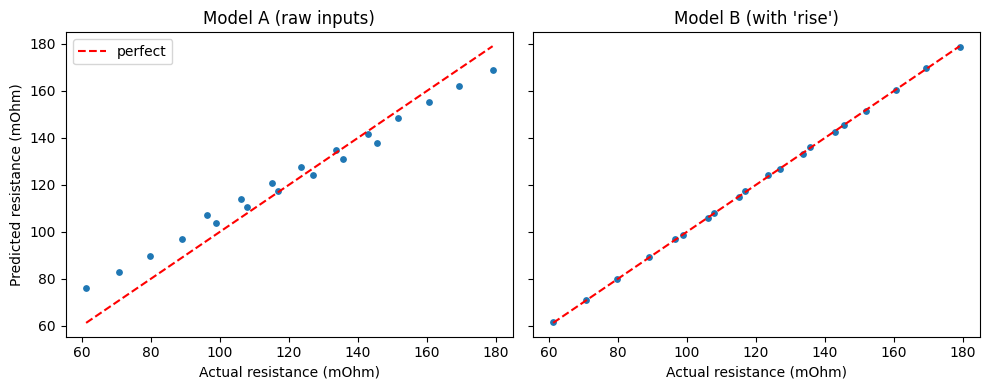

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for a, pred, title in [(ax[0], predA, "Model A (raw inputs)"),
                       (ax[1], predB, "Model B (with 'rise')")]:
    a.scatter(test.resistance, pred, s=15)
    lim = [test.resistance.min(), test.resistance.max()]
    a.plot(lim, lim, "r--", label="perfect")
    a.set_title(title)
    a.set_xlabel("Actual resistance (mOhm)")
ax[0].set_ylabel("Predicted resistance (mOhm)")
ax[0].legend()
plt.tight_layout()
plt.show()

## Step 8: Predict for ANY metal
Give the model a metal's resistivity and alpha, plus a temperature.

In [8]:
def predict_resistance(resistivity, alpha, temperature):
    rise = resistivity * alpha * (temperature - 20)
    X = pd.DataFrame([[resistivity, rise]], columns=featuresB)
    return modelB.predict(X)[0]

# Titanium: resistivity about 420 nOhm.m, alpha about 0.0035 /C
print("Titanium at 100 C ->", round(predict_resistance(420, 0.0035, 100), 1), "mOhm")

# Your own metal
print("Custom metal at 150 C ->", round(predict_resistance(50, 0.004, 150), 1), "mOhm")

Titanium at 100 C -> 537.7 mOhm
Custom metal at 150 C -> 76.0 mOhm


## Step 9: Resistance vs temperature for every metal

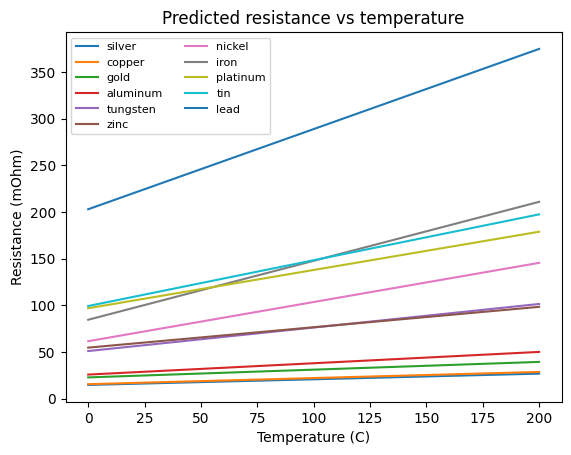

In [9]:
t = np.linspace(0, 200, 50)
for _, m in metals.iterrows():
    plt.plot(t, [predict_resistance(m.resistivity, m.alpha, v) for v in t], label=m.metal)
plt.xlabel("Temperature (C)")
plt.ylabel("Resistance (mOhm)")
plt.title("Predicted resistance vs temperature")
plt.legend(ncol=2, fontsize=8)
plt.show()

## Questions for students
1. Why did Model A score lower than Model B? (Hint: Model A can only add `ρ`, `α` and `T` separately, but the physics multiplies them.)
2. Both coefficients in Model B are close to 1. What does that tell you about the formula?
3. Why did we hide whole metals from training instead of picking random rows?
4. Add a new metal to the table (look up its ρ and α) and check the prediction.
5. Extension: add wire **length** and **area** as inputs (`R = ρL/A`).